In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/air_quality.csv")
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

In [3]:
#[PP02] Create a working copy of the dataset
df_clean = df.copy()

In [4]:
#[PP03] Check the working dataset
df_clean.shape

(43824, 14)

In [5]:
#[PP04] Check missing values
df_clean.isnull().sum()

No             0
year           0
month          0
day            0
hour           0
pm2.5       2067
DEWP           0
TEMP           0
PRES           0
cbwd           0
Iws            0
Is             0
Ir             0
datetime       0
dtype: int64

In [6]:
#[PP05] Calculate missing value percentage
(df_clean.isnull().sum() / len(df_clean)) * 100

No          0.000000
year        0.000000
month       0.000000
day         0.000000
hour        0.000000
pm2.5       4.716594
DEWP        0.000000
TEMP        0.000000
PRES        0.000000
cbwd        0.000000
Iws         0.000000
Is          0.000000
Ir          0.000000
datetime    0.000000
dtype: float64

In [9]:
#[PP06] Check missing PM2.5 values by year
df_clean.groupby("year")["pm2.5"].apply(
    lambda x: x.isnull().sum()
)

year
2010    669
2011    728
2012    489
2013     82
2014     99
Name: pm2.5, dtype: int64

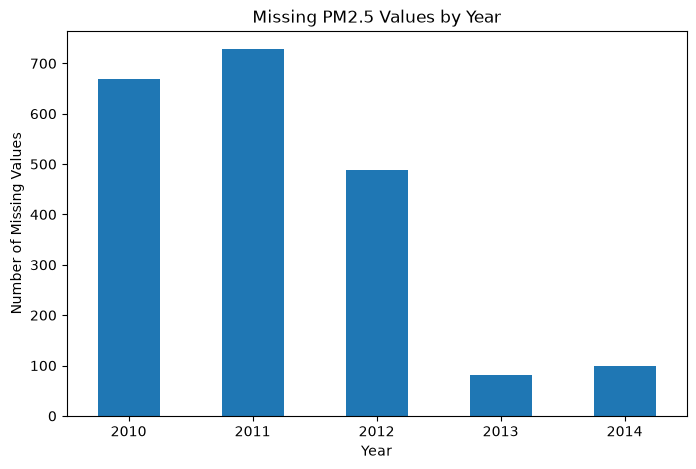

In [10]:
#[PP07] Visualise missing values by year

missing_by_year = df_clean.groupby("year")["pm2.5"].apply(
    lambda x: x.isnull().sum()
)

missing_by_year.plot(kind="bar", figsize=(8, 5))

plt.title("Missing PM2.5 Values by Year")
plt.xlabel("Year")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)
plt.show()

In [11]:
#[PP08] Check PM2.5 statistical range
df_clean["pm2.5"].describe()

count    41757.000000
mean        98.613215
std         92.050387
min          0.000000
25%         29.000000
50%         72.000000
75%        137.000000
max        994.000000
Name: pm2.5, dtype: float64

In [12]:
#[PP09] Display the 10 highest PM2.5 readings
df_clean.nlargest(10, "pm2.5")[["datetime", "pm2.5"]]

,datetime,pm2.5
18049,2012-01-23 01:00:00,994.0
1057,2010-02-14 01:00:00,980.0
18050,2012-01-23 02:00:00,972.0
26588,2013-01-12 20:00:00,886.0
26590,2013-01-12 22:00:00,858.0
26589,2013-01-12 21:00:00,852.0
26584,2013-01-12 16:00:00,845.0
26587,2013-01-12 19:00:00,824.0
26585,2013-01-12 17:00:00,810.0
26591,2013-01-12 23:00:00,805.0


In [13]:
#[PP10] Inspect observations around extreme pollution event

df_clean.loc[18045:18055, ["datetime", "pm2.5"]]

,datetime,pm2.5
18045,2012-01-22 21:00:00,193.0
18046,2012-01-22 22:00:00,182.0
18047,2012-01-22 23:00:00,161.0
18048,2012-01-23 00:00:00,225.0
18049,2012-01-23 01:00:00,994.0
18050,2012-01-23 02:00:00,972.0
18051,2012-01-23 03:00:00,430.0
18052,2012-01-23 04:00:00,296.0
18053,2012-01-23 05:00:00,284.0
18054,2012-01-23 06:00:00,285.0


In [14]:
df_clean.loc[26580:26595, ["datetime", "pm2.5"]]

,datetime,pm2.5
26580,2013-01-12 12:00:00,472.0
26581,2013-01-12 13:00:00,458.0
26582,2013-01-12 14:00:00,529.0
26583,2013-01-12 15:00:00,802.0
26584,2013-01-12 16:00:00,845.0
26585,2013-01-12 17:00:00,810.0
26586,2013-01-12 18:00:00,776.0
26587,2013-01-12 19:00:00,824.0
26588,2013-01-12 20:00:00,886.0
26589,2013-01-12 21:00:00,852.0


In [15]:
#[PP11] Count zero PM2.5 readings
(df_clean["pm2.5"] == 0).sum()

np.int64(2)

In [16]:
#[PP12] Check whether timestamps are continuous
df_clean["datetime"].diff().value_counts()

datetime
0 days 01:00:00    43823
Name: count, dtype: int64

In [17]:
#[PP13] Check missing values
df_clean.isnull().sum()

No             0
year           0
month          0
day            0
hour           0
pm2.5       2067
DEWP           0
TEMP           0
PRES           0
cbwd           0
Iws            0
Is             0
Ir             0
datetime       0
dtype: int64

In [ ]:
#[PP14] Verify dataset structure
df_clean.shape, df_clean.columns.tolist()

((43824, 14),
 ['No',
  'year',
  'month',
  'day',
  'hour',
  'pm2.5',
  'DEWP',
  'TEMP',
  'PRES',
  'cbwd',
  'Iws',
  'Is',
  'Ir',
  'datetime'])

In [19]:
#[PP15] Remove record number column
df_clean = df_clean.drop(columns=["No"])

In [20]:
df_clean.shape

(43824, 13)

In [21]:
#[PP16] Check wind direction categories
df_clean["cbwd"].value_counts()

cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64

In [22]:
#[PP17] Apply one-hot encoding
df_clean = pd.get_dummies(df_clean, columns=["cbwd"], dtype=int)

In [23]:
#[PP18] Verify encoded dataset
df_clean.shape, df_clean.columns.tolist()

((43824, 16),
 ['year',
  'month',
  'day',
  'hour',
  'pm2.5',
  'DEWP',
  'TEMP',
  'PRES',
  'Iws',
  'Is',
  'Ir',
  'datetime',
  'cbwd_NE',
  'cbwd_NW',
  'cbwd_SE',
  'cbwd_cv'])

In [24]:
#[PP19] Validate one-hot encoding
df_clean[["cbwd_NE", "cbwd_NW", "cbwd_SE", "cbwd_cv"]].sum(axis=1).value_counts()

1    43824
Name: count, dtype: int64

In [25]:
#[PP20] Inspect preprocessed dataset
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   year      43824 non-null  int64         
 1   month     43824 non-null  int64         
 2   day       43824 non-null  int64         
 3   hour      43824 non-null  int64         
 4   pm2.5     41757 non-null  float64       
 5   DEWP      43824 non-null  int64         
 6   TEMP      43824 non-null  float64       
 7   PRES      43824 non-null  float64       
 8   Iws       43824 non-null  float64       
 9   Is        43824 non-null  int64         
 10  Ir        43824 non-null  int64         
 11  datetime  43824 non-null  datetime64[us]
 12  cbwd_NE   43824 non-null  int64         
 13  cbwd_NW   43824 non-null  int64         
 14  cbwd_SE   43824 non-null  int64         
 15  cbwd_cv   43824 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(11)
memory usage: 5.3 MB


In [26]:
#[PP21] Inspect numerical feature statistics
df_clean.describe()

,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,datetime,cbwd_NE,cbwd_NW,cbwd_SE,cbwd_cv
count,43824.000000,43824.000000,43824.000000,43824.000000,41757.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824,43824.000000,43824.000000,43824.000000,43824.000000
mean,2012.000000,6.523549,15.727820,11.500000,98.613215,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916,2012-07-01 23:30:00,0.114024,0.322882,0.348896,0.214198
min,2010.000000,1.000000,1.000000,0.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000,2010-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000
25%,2011.000000,4.000000,8.000000,5.750000,29.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000,2011-04-02 11:45:00,0.000000,0.000000,0.000000,0.000000
50%,2012.000000,7.000000,16.000000,11.500000,72.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000,2012-07-01 23:30:00,0.000000,0.000000,0.000000,0.000000
75%,2013.000000,10.000000,23.000000,17.250000,137.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000,2013-10-01 11:15:00,0.000000,1.000000,1.000000,0.000000
max,2014.000000,12.000000,31.000000,23.000000,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000,2014-12-31 23:00:00,1.000000,1.000000,1.000000,1.000000
std,1.413842,3.448572,8.799425,6.922266,92.050387,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867,NaN,0.317844,0.467584,0.476626,0.410269


In [27]:
#[PP22] Check negative values in numerical features
df_clean[["pm2.5", "PRES", "Iws", "Is", "Ir"]].lt(0).sum()

pm2.5    0
PRES     0
Iws      0
Is       0
Ir       0
dtype: int64

In [28]:
#[PP23] Final missing-value check
df_clean.isnull().sum()

year           0
month          0
day            0
hour           0
pm2.5       2067
DEWP           0
TEMP           0
PRES           0
Iws            0
Is             0
Ir             0
datetime       0
cbwd_NE        0
cbwd_NW        0
cbwd_SE        0
cbwd_cv        0
dtype: int64

In [30]:
#[PP23] Save preprocessed dataset
df_clean.to_csv("../data/processed/air_quality_cleaned.csv", index=False)